# Regresión logística: tenencia de cuenta financiera
**Proyecto de Ciencia de Datos — Grupo 10**  
Isaias Carte y Rodrigo Ramirez

Se utiliza la base validada de la Fase 1 para predecir `account_fin` con seis características individuales. Se construye una partición estratificada 80/20, un baseline de clase mayoritaria y una regresión logística. Se evalúa especialmente la detección de personas **sin cuenta (clase 0)** y se interpretan asociaciones ajustadas mediante coeficientes y odds ratios.

No se incorpora país ni pesos como predictores. No se entrena Random Forest. El entrenamiento y las métricas son **sin ponderación muestral**: describen la muestra de prueba, no porcentajes representativos de población regional.

## 1. Carga y validación
Las rutas son relativas a la raíz o a `notebooks/`. El dataset procesado se lee sin modificarlo. No se repite la limpieza ni se eliminan nuevas filas. Se verifica su correspondencia con la base validada y se conservan índices de fila para reproducir exactamente la partición en una futura comparación de modelos.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score, make_scorer, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path(".") if Path("src/evaluation.py").is_file() else Path("..")
assert (ROOT / "src/evaluation.py").is_file(), "Abrir desde la raíz o notebooks/."
sys.path.insert(0, str(ROOT))
from src.data_processing import LABELS, MODEL_COLUMNS, VALID_CODES
from src.evaluation import evaluate_binary_classifier

DATA_PATH = ROOT / "data/processed/findex_lac_clean.csv"
FIGURES = ROOT / "outputs/figures"
METRICS = ROOT / "outputs/metrics"
TABLES = ROOT / "outputs/tables"
MODELS = ROOT / "models"
for folder in [FIGURES, METRICS, TABLES, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 100})
pd.set_option("display.max_columns", 15)

source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
phase1 = json.loads((ROOT / "docs/verificaciones_fase1.json").read_text(encoding="utf-8"))
assert source_hash == phase1["datos_procesados_sha256"], "La base difiere de la validada en Fase 1."
data = pd.read_csv(DATA_PATH)
predictors = ["age", "female", "educ", "inc_q", "emp_in", "mobileowner"]
target = "account_fin"
assert all(c in data for c in [target] + predictors)
missing = data[[target] + predictors].isna().sum().rename_axis("variable").to_frame("faltantes")
display(missing)
assert missing.faltantes.sum() == 0, "No modificar la limpieza aquí; revisar la base de Fase 1."
assert np.isfinite(data[[target] + predictors].to_numpy()).all()
for column, domain in VALID_CODES.items():
    assert set(data[column].unique()) <= domain, f"Código inesperado: {column}"
assert set(data.account_fin.unique()) == {0, 1}
assert data.age.between(15, 99).all() and data.age.eq(data.age.round()).all()
X = data[predictors].copy()
y = data[target].copy()
assert list(X.columns) == predictors
print(f"Base validada: {len(data):,} filas; X: {X.shape}; y: {y.shape}.")

,faltantes
variable,
account_fin,0
age,0
female,0
educ,0
inc_q,0
emp_in,0
mobileowner,0


Base validada: 18,927 filas; X: (18927, 6); y: (18927,).


## 2. Codificación y referencias
`account_fin`: **0 = Sin cuenta**, **1 = Con cuenta**, según la definición oficial validada. Las probabilidades del modelo corresponden a la clase 1. Las cinco variables categóricas se codifican con [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html), omitiendo una referencia por variable. Aunque educación e ingreso tienen orden, se usan indicadores separados para no imponer distancias iguales entre sus categorías.

| Variable | Valores y tratamiento | Referencia |
|---|---|---|
| `age` | Continua en años; se resta la media **de entrenamiento**, sin dividir por su desviación estándar. Su coeficiente corresponde a un año adicional. | No aplica; intercepto a la edad media de entrenamiento |
| `female` | 1 = Hombre; 2 = Mujer; One-Hot | Hombre (1) |
| `educ` | 1 = Primaria o menos; 2 = Secundaria; 3 = Terciaria o más; One-Hot | Primaria o menos (1) |
| `inc_q` | Quintiles 1–5 relativos a cada economía; One-Hot | Quintil 1 (1) |
| `emp_in` | 0 = Fuera de fuerza laboral; 1 = En fuerza laboral; One-Hot | Fuera de fuerza laboral (0) |
| `mobileowner` | 1 = Tiene teléfono; 2 = No tiene teléfono; One-Hot | No tiene teléfono (2) |

La edad 99 conserva el significado **99+** de la fuente. Su representación como 99 es una aproximación, ya heredada de la base validada. La relación entre edad y log-odds se supone lineal en esta primera especificación; no equivale a una relación lineal entre edad y probabilidad.

No se realizan imputaciones, selección de variables ni ajustes de hiperparámetros con el conjunto de prueba.

## 3. Partición estratificada 80/20
Se usa `random_state=42` y `stratify=y`. Los tamaños enteros pueden apartarse levemente del 80/20 exacto. La separación se realiza **antes** de ajustar el preprocesamiento: la media de edad se aprende solo de entrenamiento. Las categorías y referencias se fijan según el diccionario, no por resultados de prueba.

Esta división aleatoria evalúa personas nuevas de la mezcla de economías observada; no mide generalización a países no vistos. Se guarda `model_split_indices.csv`, con índice base cero del CSV procesado y orden dentro de cada partición, para que el siguiente modelo pueda usar las mismas observaciones.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y,
)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_train.index) | set(X_test.index) == set(data.index)
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
split_rows = []
for name, subset in [("entrenamiento", y_train), ("prueba", y_test)]:
    for label in [0, 1]:
        count = int(subset.eq(label).sum())
        split_rows.append({"particion": name, "clase": label, "etiqueta": LABELS[target][label],
                           "n": count, "porcentaje_particion": 100 * count / len(subset),
                           "n_particion": len(subset)})
split_summary = pd.DataFrame(split_rows)
split_summary.to_csv(TABLES / "logistic_split_summary.csv", index=False)
split_indices = pd.concat([
    pd.DataFrame({"fila_dataset": subset.index, "particion": name,
                  "orden_en_particion": np.arange(len(subset))})
    for name, subset in [("entrenamiento", y_train), ("prueba", y_test)]
], ignore_index=True)
split_indices.to_csv(TABLES / "model_split_indices.csv", index=False)
display(split_summary)
print(f"Entrenamiento: {len(X_train):,}; prueba: {len(X_test):,}.")

,particion,clase,etiqueta,n,porcentaje_particion,n_particion
0,entrenamiento,0,No tiene cuenta,7549,49.858001,15141
1,entrenamiento,1,Tiene cuenta,7592,50.141999,15141
2,prueba,0,No tiene cuenta,1888,49.867934,3786
3,prueba,1,Tiene cuenta,1898,50.132066,3786


Entrenamiento: 15,141; prueba: 3,786.


## 4. Baseline: clase mayoritaria de entrenamiento
Se ajusta `DummyClassifier(strategy="most_frequent")` únicamente con entrenamiento. La mayoría se determina en esa partición. Este baseline no aprende relaciones con los predictores y permite evaluar si la regresión mejora respecto de predecir siempre la misma clase.

In [3]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_p1 = baseline.predict_proba(X_test)[:, list(baseline.classes_).index(1)]
baseline_overall, baseline_classes = evaluate_binary_classifier(y_test, baseline_pred, baseline_p1, "Baseline mayoritario")
majority = int(y_train.value_counts().idxmax())
assert np.all(baseline_pred == majority)
display(pd.DataFrame([baseline_overall]))
display(baseline_classes)
display(Markdown(f"El baseline predice siempre **{LABELS[target][majority]} ({majority})** y alcanza "
                 f"**{100 * baseline_overall['accuracy']:.2f}% de accuracy** en prueba. "
                 "La precisión de una clase sin predicciones se registra como 0 por convención (`zero_division=0`); "
                 "no significa que esa precisión sea estimable con predicciones positivas. Las probabilidades constantes producen ROC-AUC = 0,5."))

,modelo,n_prueba,accuracy,roc_auc_clase_1,f1_macro
0,Baseline mayoritario,3786,0.501321,0.5,0.33392


,modelo,clase,etiqueta,precision,recall,f1_score,n_real,roc_auc_uno_contra_resto
0,Baseline mayoritario,0,Sin cuenta,0.000000,0.0,0.00000,1888,0.5
1,Baseline mayoritario,1,Con cuenta,0.501321,1.0,0.66784,1898,0.5


El baseline predice siempre **Tiene cuenta (1)** y alcanza **50.13% de accuracy** en prueba. La precisión de una clase sin predicciones se registra como 0 por convención (`zero_division=0`); no significa que esa precisión sea estimable con predicciones positivas. Las probabilidades constantes producen ROC-AUC = 0,5.

## 5. Pipeline y entrenamiento de la regresión logística
El `ColumnTransformer` centra edad y aplica One-Hot a las categorías; `remainder="drop"` evita incorporar columnas adicionales. La `Pipeline` ajusta conjuntamente preprocesamiento y clasificador **solo con entrenamiento**.

Se utiliza [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) con solver `lbfgs`, regularización **L2**, `C=1.0`, intercepto y hasta 2.000 iteraciones. Se fija `tol=1e-8` y se comprueba la convergencia. Es una especificación inicial, sin búsqueda de hiperparámetros. No se usan `class_weight` ni `sample_weight`; los coeficientes son regularizados y no estimaciones inferenciales con pruebas de significancia.

In [4]:
categorical = ["female", "educ", "inc_q", "emp_in", "mobileowner"]
category_domains = [[1, 2], [1, 2, 3], [1, 2, 3, 4, 5], [0, 1], [1, 2]]
reference_values = [1, 1, 1, 0, 2]
preprocessing = ColumnTransformer([
    ("edad", StandardScaler(with_std=False), ["age"]),
    ("categorias", OneHotEncoder(categories=category_domains, drop=reference_values,
                                 handle_unknown="error"), categorical),
], remainder="drop")
logistic = Pipeline([
    ("preprocesamiento", preprocessing),
    ("modelo", LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000, tol=1e-8,
                                  class_weight=None, random_state=42)),
])
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    logistic.fit(X_train, y_train)

fitted_preprocessing = logistic.named_steps["preprocesamiento"]
fitted_model = logistic.named_steps["modelo"]
age_transformer = fitted_preprocessing.named_transformers_["edad"]
encoder = fitted_preprocessing.named_transformers_["categorias"]
assert fitted_model.classes_.tolist() == [0, 1]
assert np.isclose(age_transformer.mean_[0], X_train.age.mean())
assert int(age_transformer.n_samples_seen_) == len(X_train)
assert fitted_model.n_iter_.max() < fitted_model.max_iter
feature_names = fitted_preprocessing.get_feature_names_out()
print("Características después del preprocesamiento:", feature_names.tolist())
print("Media de edad aprendida en train:", float(age_transformer.mean_[0]))
print("Iteraciones:", fitted_model.n_iter_.tolist())

Características después del preprocesamiento: ['edad__age', 'categorias__female_2', 'categorias__educ_2', 'categorias__educ_3', 'categorias__inc_q_2', 'categorias__inc_q_3', 'categorias__inc_q_4', 'categorias__inc_q_5', 'categorias__emp_in_1', 'categorias__mobileowner_1']
Media de edad aprendida en train: 41.87992867049733
Iteraciones: [122]


## 6. Predicciones y evaluación sobre prueba
Se conserva el umbral predeterminado **P(con cuenta) > 0,5** para predecir clase 1; los empates se asignan a clase 0, conforme a `predict` en este clasificador binario. No se optimiza el umbral con prueba.

Precision, recall y F1 se calculan **para cada clase por separado**. Para las personas sin cuenta, recall indica qué proporción de las personas realmente sin cuenta se detecta; precision indica qué proporción de las predichas sin cuenta realmente lo está. ROC-AUC utiliza probabilidades, no etiquetas; al evaluar la clase 0 se usa `P(sin cuenta) = 1 - P(con cuenta)`. Todas las métricas siguientes son no ponderadas.

In [5]:
y_pred = logistic.predict(X_test)
probabilities = logistic.predict_proba(X_test)
p1 = probabilities[:, list(fitted_model.classes_).index(1)]
p0 = probabilities[:, list(fitted_model.classes_).index(0)]
assert np.allclose(p0 + p1, 1)
assert np.array_equal(y_pred, (p1 > 0.5).astype(int))
logistic_overall, logistic_classes = evaluate_binary_classifier(y_test, y_pred, p1, "Regresión logística")
comparison = pd.DataFrame([baseline_overall, logistic_overall])
per_class_metrics = pd.concat([baseline_classes, logistic_classes], ignore_index=True)
comparison.to_csv(METRICS / "logistic_model_comparison.csv", index=False)
per_class_metrics.to_csv(METRICS / "logistic_metrics.csv", index=False)
predictions = pd.DataFrame({"fila_dataset": X_test.index, "account_fin_real": y_test.to_numpy(),
                            "account_fin_predicho": y_pred, "prob_sin_cuenta": p0,
                            "prob_con_cuenta": p1, "baseline_predicho": baseline_pred})
predictions.to_csv(METRICS / "logistic_test_predictions.csv", index=False)
display(comparison)
display(per_class_metrics)

,modelo,n_prueba,accuracy,roc_auc_clase_1,f1_macro
0,Baseline mayoritario,3786,0.501321,0.500000,0.333920
1,Regresión logística,3786,0.641574,0.698089,0.641426


,modelo,clase,etiqueta,precision,recall,f1_score,n_real,roc_auc_uno_contra_resto
0,Baseline mayoritario,0,Sin cuenta,0.000000,0.000000,0.000000,1888,0.500000
1,Baseline mayoritario,1,Con cuenta,0.501321,1.000000,0.667840,1898,0.500000
2,Regresión logística,0,Sin cuenta,0.645799,0.622881,0.634133,1888,0.698089
3,Regresión logística,1,Con cuenta,0.637659,0.660169,0.648719,1898,0.698089


### Matriz de confusión
Filas = clase real; columnas = clase predicha. Se muestran conteos de personas, con el mismo orden de etiquetas en ambos ejes.

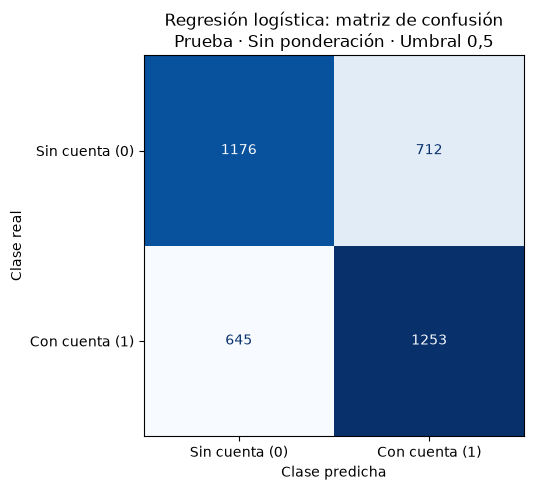

In [6]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_table = pd.DataFrame(cm, index=["real_sin_cuenta", "real_con_cuenta"],
                        columns=["predicho_sin_cuenta", "predicho_con_cuenta"])
cm_table.to_csv(METRICS / "logistic_confusion_matrix.csv", index_label="clase_real")
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=["Sin cuenta (0)", "Con cuenta (1)"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d",
)
ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
ax.set_title("Regresión logística: matriz de confusión\nPrueba · Sin ponderación · Umbral 0,5")
fig.tight_layout()
fig.savefig(FIGURES / "logistic_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close(fig)

In [7]:
no_account = logistic_classes.loc[logistic_classes.clase.eq(0)].iloc[0]
display(Markdown(
    f"Se detectan **{cm[0, 0]:,} de {cm[0].sum():,} personas sin cuenta** "
    f"(recall **{100 * no_account.recall:.2f}%**); {cm[0, 1]:,} se clasifican como con cuenta. "
    f"De las personas predichas sin cuenta, **{100 * no_account.precision:.2f}%** realmente no tiene cuenta."
))

# Se considera positiva la clase 0 (sin cuenta): TP=cm[0,0], TN=cm[1,1].
tp_no_account, fn_no_account = int(cm[0, 0]), int(cm[0, 1])
fp_no_account, tn_no_account = int(cm[1, 0]), int(cm[1, 1])
sensitivity_no_account = tp_no_account / (tp_no_account + fn_no_account)
specificity_no_account = tn_no_account / (tn_no_account + fp_no_account)
assert np.isclose(sensitivity_no_account, no_account.recall)
assert np.isclose(specificity_no_account, logistic_classes.loc[logistic_classes.clase.eq(1), "recall"].iloc[0])
holdout_detection = pd.DataFrame([{
    "clase_positiva": 0, "etiqueta": "Sin cuenta", "n_prueba": len(y_test),
    "verdaderos_positivos": tp_no_account, "falsos_negativos": fn_no_account,
    "falsos_positivos": fp_no_account, "verdaderos_negativos": tn_no_account,
    "sensibilidad": sensitivity_no_account, "especificidad": specificity_no_account,
}])
holdout_detection.to_csv(METRICS / "logistic_sensitivity_specificity.csv", index=False)
display(holdout_detection)
display(Markdown(
    f"Tomando **sin cuenta como clase positiva**, la sensibilidad es **{100 * sensitivity_no_account:.2f}%** "
    f"({tp_no_account}/{tp_no_account + fn_no_account}) y la especificidad es **{100 * specificity_no_account:.2f}%** "
    f"({tn_no_account}/{tn_no_account + fp_no_account}). Esta última mide qué proporción de las personas "
    "realmente con cuenta se clasifica correctamente como con cuenta; no es la precisión de la clase sin cuenta."
))


Se detectan **1,176 de 1,888 personas sin cuenta** (recall **62.29%**); 712 se clasifican como con cuenta. De las personas predichas sin cuenta, **64.58%** realmente no tiene cuenta.

,clase_positiva,etiqueta,n_prueba,verdaderos_positivos,falsos_negativos,falsos_positivos,verdaderos_negativos,sensibilidad,especificidad
0,0,Sin cuenta,3786,1176,712,645,1253,0.622881,0.660169


Tomando **sin cuenta como clase positiva**, la sensibilidad es **62.29%** (1176/1888) y la especificidad es **66.02%** (1253/1898). Esta última mide qué proporción de las personas realmente con cuenta se clasifica correctamente como con cuenta; no es la precisión de la clase sin cuenta.

### Curva ROC
Se presenta cada clase como positiva para hacer explícita la evaluación de personas sin cuenta. Las dos áreas coinciden en este problema binario al invertir simultáneamente el objetivo y su probabilidad; no representan dos modelos distintos.

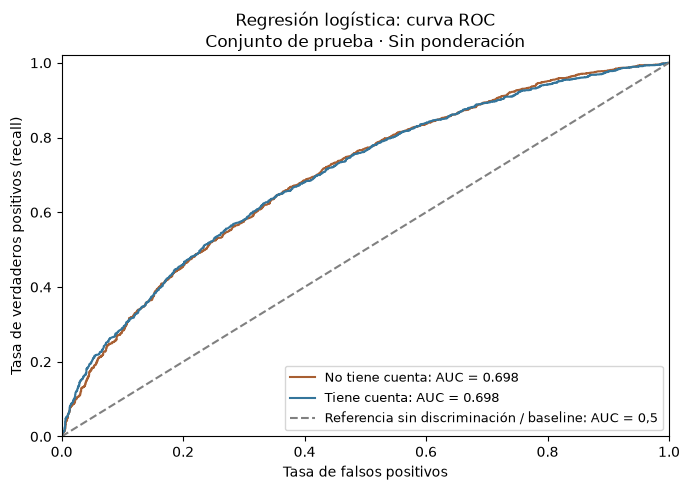

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
roc_rows = []
for label, scores, color in [(0, p0, "#a85f32"), (1, p1, "#34759b")]:
    fpr, tpr, thresholds = roc_curve(y_test.eq(label), scores)
    auc = float(logistic_classes.loc[logistic_classes.clase.eq(label), "roc_auc_uno_contra_resto"].iloc[0])
    ax.plot(fpr, tpr, label=f"{LABELS[target][label]}: AUC = {auc:.3f}", color=color)
    roc_rows.append(pd.DataFrame({"clase_positiva": label, "fpr": fpr, "tpr": tpr, "umbral": thresholds}))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Referencia sin discriminación / baseline: AUC = 0,5")
ax.set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos (recall)",
       title="Regresión logística: curva ROC\nConjunto de prueba · Sin ponderación", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout(); fig.savefig(FIGURES / "logistic_roc_curve.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close(fig)
pd.concat(roc_rows, ignore_index=True).to_csv(METRICS / "logistic_roc_points.csv", index=False)

In [9]:
gain = 100 * (logistic_overall["accuracy"] - baseline_overall["accuracy"])
display(Markdown(
    f"La regresión alcanza **{100 * logistic_overall['accuracy']:.2f}% de accuracy**, "
    f"frente a **{100 * baseline_overall['accuracy']:.2f}%** del baseline: "
    f"una diferencia de **{gain:.2f} puntos porcentuales**. Su ROC-AUC es **{logistic_overall['roc_auc_clase_1']:.4f}**. "
    f"El recall de personas sin cuenta pasa de **{100 * baseline_classes.loc[baseline_classes.clase.eq(0), 'recall'].iloc[0]:.2f}%** "
    f"a **{100 * no_account.recall:.2f}%**. "
    "La mejora muestra capacidad predictiva frente a la regla mayoritaria en esta partición; no demuestra causalidad ni generalización a países no vistos."
))

La regresión alcanza **64.16% de accuracy**, frente a **50.13%** del baseline: una diferencia de **14.03 puntos porcentuales**. Su ROC-AUC es **0.6981**. El recall de personas sin cuenta pasa de **0.00%** a **62.29%**. La mejora muestra capacidad predictiva frente a la regla mayoritaria en esta partición; no demuestra causalidad ni generalización a países no vistos.

## 7. Coeficientes, referencias y odds ratios
Los coeficientes modelan el logaritmo de las **odds de tener cuenta**. `odds ratio = exp(coeficiente)` compara odds, no probabilidades, **manteniendo constantes las demás variables**. Para cada categoría se compara con su referencia; para edad, un año adicional. OR > 1 se asocia con mayores odds de tener cuenta y OR < 1 con menores odds.

El intercepto representa el perfil de referencia a la edad media de entrenamiento, sin interpretarse como una característica adicional. Se exportan todos los coeficientes transformados y el intercepto; las categorías omitidas se documentan aparte, ya que no tienen coeficientes estimados independientes. Se mantiene el orden edad, sexo, educación, ingreso, participación laboral y teléfono para facilitar lectura. No se ordena la importancia por magnitud de coeficientes con unidades diferentes.

Las estimaciones están regularizadas con L2. No se calculan intervalos de confianza, errores estándar ni significancia estadística; no se presenta el orden de OR como una jerarquía universal de importancia.

In [10]:
reference_rows = []
for variable, categories, drop_idx in zip(categorical, encoder.categories_, encoder.drop_idx_):
    reference_code = int(categories[drop_idx])
    reference_rows.append({"variable": variable, "codigo_referencia": reference_code,
                           "categoria_referencia": LABELS[variable][reference_code]})
references = pd.DataFrame(reference_rows)
references.to_csv(TABLES / "logistic_reference_categories.csv", index=False)
display(references)

feature_rows = [{"caracteristica_transformada": feature_names[0], "variable": "age",
                 "variable_categoria": "Edad: un año adicional", "categoria_referencia": "Edad centrada en media de entrenamiento",
                 "unidad_comparacion": "Un año adicional"}]
position = 1
for variable, categories, drop_idx in zip(categorical, encoder.categories_, encoder.drop_idx_):
    reference_label = LABELS[variable][int(categories[drop_idx])]
    for idx, value in enumerate(categories):
        if idx == drop_idx:
            continue
        feature_rows.append({"caracteristica_transformada": feature_names[position], "variable": variable,
                             "variable_categoria": LABELS[variable][int(value)], "categoria_referencia": reference_label,
                             "unidad_comparacion": f"{LABELS[variable][int(value)]} frente a {reference_label}"})
        position += 1
assert position == len(feature_names) == fitted_model.coef_.shape[1]
coefficients = pd.DataFrame(feature_rows)
coefficients["coeficiente"] = fitted_model.coef_[0]
coefficients["odds_ratio"] = np.exp(coefficients.coeficiente)
coefficients["direccion_asociacion"] = np.select(
    [coefficients.coeficiente > 0, coefficients.coeficiente < 0],
    ["Mayores odds de tener cuenta", "Menores odds de tener cuenta"], default="Sin cambio en odds",
)
intercept = pd.DataFrame([{
    "caracteristica_transformada": "intercepto", "variable": "intercepto", "variable_categoria": "Intercepto",
    "categoria_referencia": "Perfil de referencia a la edad media de entrenamiento",
    "unidad_comparacion": "Odds base del perfil; no es una comparación entre categorías",
    "coeficiente": float(fitted_model.intercept_[0]), "odds_ratio": float(np.exp(fitted_model.intercept_[0])),
    "direccion_asociacion": "Intercepto: odds base, no asociación de un predictor",
}])
coefficient_table = pd.concat([coefficients, intercept], ignore_index=True)
coefficient_table.to_csv(TABLES / "logistic_coefficients.csv", index=False)
display(coefficient_table[["variable", "variable_categoria", "categoria_referencia", "coeficiente", "odds_ratio", "direccion_asociacion"]])

,variable,codigo_referencia,categoria_referencia
0,female,1,Hombre
1,educ,1,Primaria o menos
2,inc_q,1,Quintil 1
3,emp_in,0,Fuera de fuerza laboral
4,mobileowner,2,No tiene teléfono


,variable,variable_categoria,categoria_referencia,coeficiente,odds_ratio,direccion_asociacion
0,age,Edad: un año adicional,Edad centrada en media de entrenamiento,0.018899,1.019078,Mayores odds de tener cuenta
1,female,Mujer,Hombre,-0.059234,0.942486,Menores odds de tener cuenta
2,educ,Secundaria,Primaria o menos,0.589677,1.803406,Mayores odds de tener cuenta
3,educ,Terciaria o más,Primaria o menos,1.444080,4.237951,Mayores odds de tener cuenta
4,inc_q,Quintil 2,Quintil 1,0.224922,1.252225,Mayores odds de tener cuenta
5,inc_q,Quintil 3,Quintil 1,0.388932,1.475404,Mayores odds de tener cuenta
6,inc_q,Quintil 4,Quintil 1,0.525927,1.692026,Mayores odds de tener cuenta
7,inc_q,Quintil 5,Quintil 1,0.845680,2.329562,Mayores odds de tener cuenta
8,emp_in,En fuerza laboral,Fuera de fuerza laboral,0.442737,1.556963,Mayores odds de tener cuenta
9,mobileowner,Tiene teléfono,No tiene teléfono,0.876807,2.403215,Mayores odds de tener cuenta


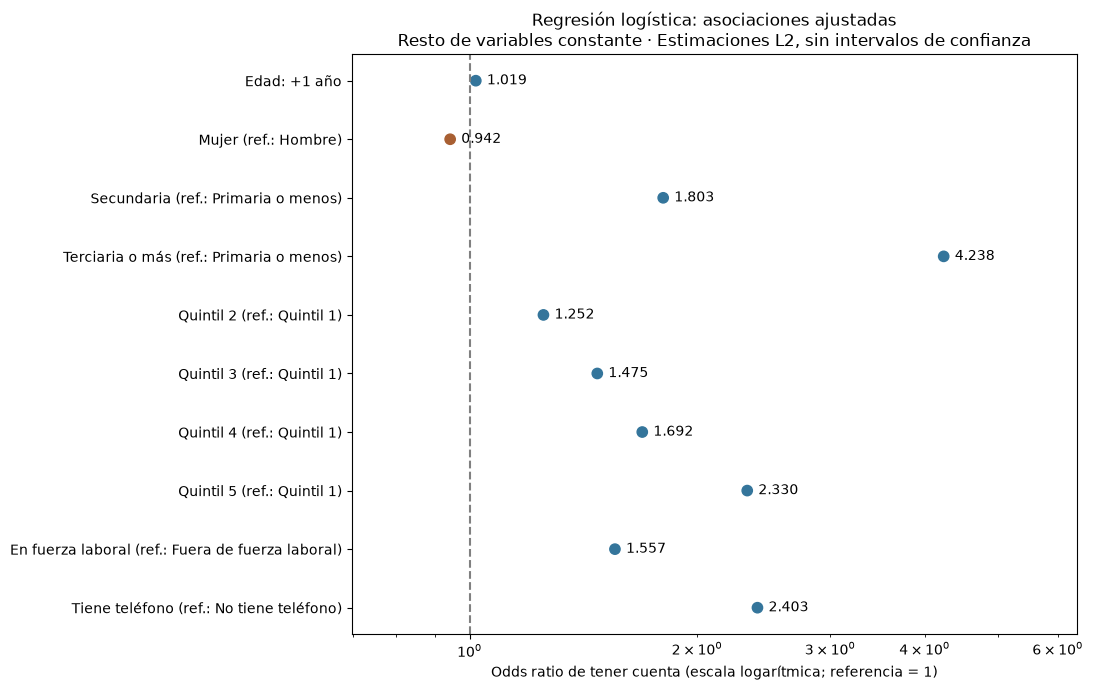

In [11]:
plot_labels = coefficients.apply(
    lambda row: "Edad: +1 año" if row.variable == "age" else f"{row.variable_categoria} (ref.: {row.categoria_referencia})", axis=1,
)
fig, ax = plt.subplots(figsize=(11, 7))
positions = np.arange(len(coefficients))
ax.scatter(coefficients.odds_ratio, positions,
           c=np.where(coefficients.coeficiente.gt(0), "#34759b", "#a85f32"), s=55)
ax.axvline(1, color="gray", linestyle="--")
ax.set_xscale("log")
ax.set_yticks(positions, labels=plot_labels)
ax.invert_yaxis()
for pos, value in zip(positions, coefficients.odds_ratio):
    ax.annotate(f"{value:.3f}", (value, pos), xytext=(8, 0), textcoords="offset points", va="center")
ax.set_xlim(coefficients.odds_ratio.min() / 1.35, coefficients.odds_ratio.max() * 1.5)
ax.set_xlabel("Odds ratio de tener cuenta (escala logarítmica; referencia = 1)")
ax.set_title("Regresión logística: asociaciones ajustadas\nResto de variables constante · Estimaciones L2, sin intervalos de confianza")
fig.tight_layout(); fig.savefig(FIGURES / "logistic_odds_ratios.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close(fig)

In [12]:
# Interpretación construida a partir de los coeficientes efectivos, sin fijar resultados a mano.
for variable in ["educ", "inc_q", "mobileowner", "female", "emp_in", "age"]:
    rows = coefficients.loc[coefficients.variable.eq(variable)]
    statements = []
    for row in rows.itertuples():
        comparison_label = "Un año adicional" if variable == "age" else f"{row.variable_categoria} frente a {row.categoria_referencia}"
        direction = "mayores" if row.coeficiente > 0 else "menores" if row.coeficiente < 0 else "iguales"
        statements.append(f"{comparison_label}: OR **{row.odds_ratio:.3f}**, asociado con {direction} odds de tener cuenta")
    display(Markdown("; ".join(statements) + ", **manteniendo constantes las demás variables del modelo**."))
display(Markdown(
    "Estas asociaciones son ajustadas por los otros cinco predictores, pero **no por país**. "
    "Los OR de categorías se refieren a sus respectivas bases y el de edad a un año; sus magnitudes no son comparables como medida directa de importancia. "
    "Los resultados no describen efectos causales y pueden reflejar diferencias geográficas omitidas."
))

Secundaria frente a Primaria o menos: OR **1.803**, asociado con mayores odds de tener cuenta; Terciaria o más frente a Primaria o menos: OR **4.238**, asociado con mayores odds de tener cuenta, **manteniendo constantes las demás variables del modelo**.

Quintil 2 frente a Quintil 1: OR **1.252**, asociado con mayores odds de tener cuenta; Quintil 3 frente a Quintil 1: OR **1.475**, asociado con mayores odds de tener cuenta; Quintil 4 frente a Quintil 1: OR **1.692**, asociado con mayores odds de tener cuenta; Quintil 5 frente a Quintil 1: OR **2.330**, asociado con mayores odds de tener cuenta, **manteniendo constantes las demás variables del modelo**.

Tiene teléfono frente a No tiene teléfono: OR **2.403**, asociado con mayores odds de tener cuenta, **manteniendo constantes las demás variables del modelo**.

Mujer frente a Hombre: OR **0.942**, asociado con menores odds de tener cuenta, **manteniendo constantes las demás variables del modelo**.

En fuerza laboral frente a Fuera de fuerza laboral: OR **1.557**, asociado con mayores odds de tener cuenta, **manteniendo constantes las demás variables del modelo**.

Un año adicional: OR **1.019**, asociado con mayores odds de tener cuenta, **manteniendo constantes las demás variables del modelo**.

Estas asociaciones son ajustadas por los otros cinco predictores, pero **no por país**. Los OR de categorías se refieren a sus respectivas bases y el de edad a un año; sus magnitudes no son comparables como medida directa de importancia. Los resultados no describen efectos causales y pueden reflejar diferencias geográficas omitidas.

## 8. Validación cruzada estratificada de 5 folds
Se evalúa **exactamente la misma pipeline**, con los mismos seis predictores y todos sus hiperparámetros sin cambios, mediante `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`. Se utiliza **solo el conjunto de entrenamiento de 15.141 personas**; las 3.786 personas del test actual no intervienen en los folds.

[`cross_validate`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html) clona y vuelve a ajustar toda la pipeline en cada fold, incluyendo el centrado de edad. Así, cada media de edad se estima exclusivamente con las filas de ajuste de ese fold y el preprocesamiento no recibe información de su validación. Las categorías y referencias son las mismas del diccionario original. La pipeline principal ajustada sobre el entrenamiento completo se conserva.

Se calculan Accuracy, **F1 de clase 0 (sin cuenta), F1 de clase 1 (con cuenta) y F1 macro (promedio simple de ambas clases)** y ROC-AUC con probabilidades de clase 1, sin ponderación muestral. Se reportan los cinco resultados y su media y **desviación estándar muestral (`ddof=1`)**. Esta dispersión entre folds no es un intervalo de confianza. La comparación con el test es descriptiva: los modelos de los folds se ajustan con menos personas que el modelo principal. No se cambian hiperparámetros ni se selecciona un modelo usando los resultados.

En el CSV, `f1_sin_cuenta`, `f1_con_cuenta` y `f1_macro` identifican las métricas añadidas. La columna previa `f1` se conserva como alias de `f1_con_cuenta` para mantener compatibilidad con la primera validación. Los folds se generan con la misma partición de entrenamiento, orden de filas y semilla; no se altera la pipeline.

In [13]:
cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_folds = list(cv_splitter.split(X_train, y_train))
coef_before_cv = fitted_model.coef_.copy()
intercept_before_cv = fitted_model.intercept_.copy()
validation_positions = np.concatenate([validation for _, validation in cv_folds])
assert np.array_equal(np.sort(validation_positions), np.arange(len(X_train)))
for fit_positions, validation_positions_fold in cv_folds:
    assert not set(fit_positions).intersection(validation_positions_fold)
    assert set(X_train.iloc[validation_positions_fold].index).isdisjoint(X_test.index)
    assert set(y_train.iloc[fit_positions].unique()) == {0, 1}
    assert set(y_train.iloc[validation_positions_fold].unique()) == {0, 1}

with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    cv_scores = cross_validate(
        logistic, X_train, y_train, cv=cv_folds,
        scoring={
            "accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc",
            "f1_sin_cuenta": make_scorer(f1_score, pos_label=0, zero_division=0),
            "f1_con_cuenta": make_scorer(f1_score, pos_label=1, zero_division=0),
            "f1_macro": make_scorer(f1_score, average="macro", zero_division=0),
        },
        return_estimator=True, error_score="raise", n_jobs=1,
    )

fold_results = pd.DataFrame({
    "tipo": "fold", "fold": np.arange(1, 6),
    "n_ajuste": [len(fit) for fit, _ in cv_folds],
    "n_validacion": [len(validation) for _, validation in cv_folds],
    "accuracy": cv_scores["test_accuracy"],
    "f1": cv_scores["test_f1"],
    "f1_sin_cuenta": cv_scores["test_f1_sin_cuenta"],
    "f1_con_cuenta": cv_scores["test_f1_con_cuenta"],
    "f1_macro": cv_scores["test_f1_macro"],
    "roc_auc": cv_scores["test_roc_auc"],
})
metric_columns = ["accuracy", "f1", "f1_sin_cuenta", "f1_con_cuenta", "f1_macro", "roc_auc"]
assert np.allclose(fold_results.f1, fold_results.f1_con_cuenta)
assert np.allclose(fold_results.f1_macro, (fold_results.f1_sin_cuenta + fold_results.f1_con_cuenta) / 2)
assert np.isfinite(fold_results[metric_columns]).all().all()
assert fold_results[metric_columns].ge(0).all().all() and fold_results[metric_columns].le(1).all().all()
for (fit_positions, _), estimator in zip(cv_folds, cv_scores["estimator"]):
    fold_age = estimator.named_steps["preprocesamiento"].named_transformers_["edad"]
    assert np.isclose(fold_age.mean_[0], X_train.iloc[fit_positions].age.mean())
    assert int(fold_age.n_samples_seen_) == len(fit_positions)
    assert estimator.named_steps["modelo"].n_iter_.max() < fitted_model.max_iter
    assert np.array_equal(estimator.named_steps["preprocesamiento"].get_feature_names_out(), feature_names)
assert np.array_equal(fitted_model.coef_, coef_before_cv)
assert np.array_equal(fitted_model.intercept_, intercept_before_cv)
assert np.array_equal(logistic.predict(X_test), y_pred)

cv_mean = fold_results[metric_columns].mean()
cv_std = fold_results[metric_columns].std(ddof=1)
summary_rows = pd.DataFrame([
    {"tipo": "media", **cv_mean.to_dict()},
    {"tipo": "desviacion_estandar", **cv_std.to_dict()},
])
cv_results = pd.concat([fold_results, summary_rows], ignore_index=True)
for column in ["fold", "n_ajuste", "n_validacion"]:
    cv_results[column] = cv_results[column].astype("Int64")
cv_results.to_csv(METRICS / "logistic_cross_validation.csv", index=False)
display(fold_results)
test_metric_values = {
    "accuracy": logistic_overall["accuracy"], "roc_auc": logistic_overall["roc_auc_clase_1"],
    "f1": float(logistic_classes.loc[logistic_classes.clase.eq(1), "f1_score"].iloc[0]),
    "f1_sin_cuenta": float(logistic_classes.loc[logistic_classes.clase.eq(0), "f1_score"].iloc[0]),
    "f1_con_cuenta": float(logistic_classes.loc[logistic_classes.clase.eq(1), "f1_score"].iloc[0]),
    "f1_macro": logistic_overall["f1_macro"],
}
cv_summary = pd.DataFrame({"metrica": metric_columns, "media_cv": cv_mean.values,
                           "desviacion_estandar_cv": cv_std.values,
                           "test_actual": [test_metric_values[metric] for metric in metric_columns]})
cv_summary["diferencia_cv_menos_test"] = cv_summary.media_cv - cv_summary.test_actual
display(cv_summary)
for fold_index, ((_, validation_positions_fold), estimator) in enumerate(zip(cv_folds, cv_scores["estimator"])):
    fold_true = y_train.iloc[validation_positions_fold]
    fold_pred = estimator.predict(X_train.iloc[validation_positions_fold])
    for metric, options in [("f1_sin_cuenta", {"pos_label": 0}),
                            ("f1_con_cuenta", {"pos_label": 1}), ("f1_macro", {"average": "macro"})]:
        assert np.isclose(fold_results.loc[fold_index, metric], f1_score(fold_true, fold_pred, zero_division=0, **options))


,tipo,fold,n_ajuste,n_validacion,accuracy,f1,f1_sin_cuenta,f1_con_cuenta,f1_macro,roc_auc
0,fold,1,12112,3029,0.650710,0.653342,0.648037,0.653342,0.650690,0.709880
1,fold,2,12113,3028,0.648283,0.654333,0.642017,0.654333,0.648175,0.706229
2,fold,3,12113,3028,0.643329,0.642857,0.643799,0.642857,0.643328,0.695288
3,fold,4,12113,3028,0.644980,0.645097,0.644863,0.645097,0.644980,0.697865
4,fold,5,12113,3028,0.641678,0.648526,0.634557,0.648526,0.641542,0.703678


,metrica,media_cv,desviacion_estandar_cv,test_actual,diferencia_cv_menos_test
0,accuracy,0.645796,0.003676,0.641574,0.004222
1,f1,0.648831,0.005009,0.648719,0.000113
2,f1_sin_cuenta,0.642655,0.005028,0.634133,0.008522
3,f1_con_cuenta,0.648831,0.005009,0.648719,0.000113
4,f1_macro,0.645743,0.003689,0.641426,0.004317
5,roc_auc,0.702588,0.005983,0.698089,0.004499


In [14]:
display(Markdown(
    f"En cinco folds, la accuracy es **{cv_mean['accuracy']:.4f} ± {cv_std['accuracy']:.4f}**, "
    f"F1 sin cuenta **{cv_mean['f1_sin_cuenta']:.4f} ± {cv_std['f1_sin_cuenta']:.4f}**, "
    f"F1 con cuenta **{cv_mean['f1_con_cuenta']:.4f} ± {cv_std['f1_con_cuenta']:.4f}**, "
    f"F1 macro **{cv_mean['f1_macro']:.4f} ± {cv_std['f1_macro']:.4f}** y "
    f"ROC-AUC **{cv_mean['roc_auc']:.4f} ± {cv_std['roc_auc']:.4f}**. "
    f"Frente al test actual (accuracy {logistic_overall['accuracy']:.4f}; ROC-AUC {logistic_overall['roc_auc_clase_1']:.4f}), "
    f"las diferencias CV menos test son **{100 * (cv_mean['accuracy'] - logistic_overall['accuracy']):+.2f} puntos porcentuales** "
    f"y **{cv_mean['roc_auc'] - logistic_overall['roc_auc_clase_1']:+.4f}** de AUC, respectivamente."
))
display(Markdown(
    "La dispersión observada es reducida y los promedios son cercanos al test, por lo que el modelo parece estable ante estas particiones aleatorias. Esto no implica un rendimiento predictivo alto. La comparación es descriptiva, sin pruebas inferenciales ni "
    "ajustes posteriores del modelo. Esta validación aleatoria estratificada evalúa la mezcla de economías observada; "
    "no comprueba estabilidad temporal ni generalización a economías no vistas."
))

En cinco folds, la accuracy es **0.6458 ± 0.0037**, F1 sin cuenta **0.6427 ± 0.0050**, F1 con cuenta **0.6488 ± 0.0050**, F1 macro **0.6457 ± 0.0037** y ROC-AUC **0.7026 ± 0.0060**. Frente al test actual (accuracy 0.6416; ROC-AUC 0.6981), las diferencias CV menos test son **+0.42 puntos porcentuales** y **+0.0045** de AUC, respectivamente.

La dispersión observada es reducida y los promedios son cercanos al test, por lo que el modelo parece estable ante estas particiones aleatorias. Esto no implica un rendimiento predictivo alto. La comparación es descriptiva, sin pruebas inferenciales ni ajustes posteriores del modelo. Esta validación aleatoria estratificada evalúa la mezcla de economías observada; no comprueba estabilidad temporal ni generalización a economías no vistas.

## 9. Guardado y controles finales
Se guarda la pipeline completa para conservar exactamente el centrado, las categorías y el modelo ajustado. También se registran versión del entorno, parámetros, huella del dataset y archivos de salida. Los índices guardados solo son válidos para la versión del CSV identificada por esa huella.

Los controles comprueban la reconstrucción algebraica de los log-odds y probabilidades a partir de **todos** los coeficientes, la correspondencia de las métricas con la matriz de confusión y la persistencia del modelo. Esto no sustituye una evaluación futura en otra partición o economía. El conjunto de prueba ya se utilizó para esta evaluación y no debe emplearse para ajustar especificaciones repetidamente.

In [15]:
transformed_test = fitted_preprocessing.transform(X_test)
linear_predictor = np.asarray(transformed_test @ fitted_model.coef_[0]).ravel() + fitted_model.intercept_[0]
assert np.allclose(linear_predictor, logistic.decision_function(X_test))
assert np.allclose(1 / (1 + np.exp(-linear_predictor)), p1)
assert cm.sum() == len(y_test)
assert np.isclose(np.trace(cm) / cm.sum(), logistic_overall["accuracy"])
assert np.isclose(cm[0, 0] / cm[0].sum(), no_account.recall)
assert np.isclose(cm[0, 0] / cm[:, 0].sum(), no_account.precision)
assert coefficient_table.shape[0] == len(feature_names) + 1
assert np.allclose(coefficient_table.odds_ratio, np.exp(coefficient_table.coeficiente))
assert np.isfinite(coefficient_table[["coeficiente", "odds_ratio"]]).all().all()
assert np.isclose(logistic_classes.roc_auc_uno_contra_resto.iloc[0], logistic_classes.roc_auc_uno_contra_resto.iloc[1])
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == source_hash
model_path = MODELS / "logistic_regression.joblib"
joblib.dump(logistic, model_path)
restored = joblib.load(model_path)
assert np.array_equal(restored.predict(X_test), y_pred)
assert np.allclose(restored.predict_proba(X_test), probabilities)
artifact_paths = [
    FIGURES / name for name in ["logistic_confusion_matrix.png", "logistic_roc_curve.png", "logistic_odds_ratios.png"]
] + [METRICS / name for name in ["logistic_metrics.csv", "logistic_model_comparison.csv", "logistic_test_predictions.csv", "logistic_confusion_matrix.csv", "logistic_roc_points.csv", "logistic_cross_validation.csv", "logistic_sensitivity_specificity.csv"]] + [
    TABLES / name for name in ["logistic_coefficients.csv", "logistic_reference_categories.csv", "logistic_split_summary.csv", "model_split_indices.csv"]
]
assert all(path.is_file() and path.stat().st_size > 0 for path in artifact_paths)
run_info = {
    "dataset": "data/processed/findex_lac_clean.csv", "dataset_sha256": source_hash,
    "predictors": predictors, "target": target, "random_state": 42, "test_size": 0.2,
    "stratify": "account_fin", "n_train": len(y_train), "n_test": len(y_test),
    "weighting": "Sin sample_weight ni class_weight", "threshold_class_1": "P(account_fin=1) > 0.5",
    "majority_class_training": majority, "age_training_mean": float(age_transformer.mean_[0]),
    "category_references": references.to_dict("records"),
    "parameters": {"solver": "lbfgs", "penalty": "L2", "C": 1.0, "max_iter": 2000, "tol": 1e-8},
    "cross_validation": {"n_splits": 5, "shuffle": True, "random_state": 42,
                         "dataset": "Solo X_train e y_train", "f1_definitions": {"f1": "Alias de f1_con_cuenta", "f1_sin_cuenta": "Clase positiva 0",
                                            "f1_con_cuenta": "Clase positiva 1", "f1_macro": "Promedio simple de F1 por clase"},
                         "std_ddof": 1, "mean": cv_mean.to_dict(), "std": cv_std.to_dict()},
    "holdout_class_0": {"sensitivity": sensitivity_no_account, "specificity": specificity_no_account},
    "iterations": fitted_model.n_iter_.tolist(), "python": sys.version.split()[0],
    "packages": {name: importlib.metadata.version(name) for name in ["pandas", "numpy", "matplotlib", "scikit-learn", "joblib", "nbformat", "nbclient"]},
    "artifact_sha256": {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in artifact_paths},
    "model_file": str(model_path.relative_to(ROOT)),
    "checks": "Sin faltantes, separación de índices, preprocesamiento solo train, convergencia, log-odds y probabilidades reconstruidos, métricas coherentes, modelo recargado y dataset intacto",
}
(METRICS / "logistic_run_info.json").write_text(json.dumps(run_info, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print(f"Verificaciones correctas. {len(feature_names)} coeficientes de características y un intercepto exportados.")
print("Pipeline guardada en models/logistic_regression.joblib.")
print("Sin entrenamiento de Random Forest ni inclusión de país.")

Verificaciones correctas. 10 coeficientes de características y un intercepto exportados.
Pipeline guardada en models/logistic_regression.joblib.
Sin entrenamiento de Random Forest ni inclusión de país.


## 10. Resumen de resultados
La siguiente celda genera `docs/resultados_regresion_logistica.md` usando únicamente métricas y coeficientes calculados en esta ejecución. No ajusta modelos adicionales ni modifica decisiones de entrenamiento.

In [16]:
def decimal_es(value, digits=4):
    return f"{value:.{digits}f}".replace(".", ",")

def percentage_es(value):
    return decimal_es(100 * value, 2) + "%"

# Tablas construidas desde objetos ya calculados, sin valores de resultados escritos a mano.
class_lines = ["| Clase | Precision | Recall | F1 | Personas reales |", "|---|---:|---:|---:|---:|"]
for row in logistic_classes.itertuples():
    class_lines.append(f"| {row.etiqueta} | {decimal_es(row.precision)} | {decimal_es(row.recall)} | {decimal_es(row.f1_score)} | {row.n_real} |")
cv_labels = {"accuracy": "Accuracy", "f1_sin_cuenta": "F1 sin cuenta", "f1_con_cuenta": "F1 con cuenta", "f1_macro": "F1 macro", "roc_auc": "ROC-AUC"}
cv_lines = ["| Métrica | Media ± desviación estándar | Test actual |", "|---|---:|---:|"]
for metric, label in cv_labels.items():
    cv_lines.append(f"| {label} | {decimal_es(cv_mean[metric])} ± {decimal_es(cv_std[metric])} | {decimal_es(test_metric_values[metric])} |")
or_lines = ["| Característica | Referencia | Odds ratio |", "|---|---|---:|"]
for row in coefficients.itertuples():
    or_lines.append(f"| {row.variable_categoria} | {row.categoria_referencia} | {decimal_es(row.odds_ratio, 3)} |")
report = f"""# Resultados de la regresión logística — Grupo 10

## Datos y especificación

Base validada de Global Findex 2017: {len(data):,} personas de 20 economías de América Latina y el Caribe. Se usan únicamente edad, sexo, educación, quintil de ingreso, participación laboral y teléfono móvil. Pipeline original: edad centrada con la media de entrenamiento y One-Hot con referencia para las cinco variables categóricas; regresión logística L2, C=1, solver lbfgs. No se incluyen país, pesos muestrales ni otros modelos. Objetivo: 0 = sin cuenta; 1 = con cuenta.

## Desempeño holdout

Partición estratificada 80/20, semilla 42: {len(y_train):,} personas en entrenamiento y {len(y_test):,} en prueba. Con el umbral original de 0,5, accuracy = **{decimal_es(logistic_overall['accuracy'])}**, ROC-AUC = **{decimal_es(logistic_overall['roc_auc_clase_1'])}** y F1 macro = **{decimal_es(logistic_overall['f1_macro'])}**. El baseline mayoritario tiene accuracy {decimal_es(baseline_overall['accuracy'])}; la mejora es de {decimal_es(100 * (logistic_overall['accuracy'] - baseline_overall['accuracy']), 2)} puntos porcentuales.

{chr(10).join(class_lines)}

## Sensibilidad y especificidad para personas sin cuenta

Considerando **sin cuenta como clase positiva**, sensibilidad = **{percentage_es(sensitivity_no_account)}** ({tp_no_account}/{tp_no_account + fn_no_account}): proporción de personas sin cuenta detectadas. Especificidad = **{percentage_es(specificity_no_account)}** ({tn_no_account}/{tn_no_account + fp_no_account}): proporción de personas con cuenta correctamente reconocidas como con cuenta. Se omiten {fn_no_account} personas sin cuenta y se clasifican como sin cuenta {fp_no_account} personas que sí tienen cuenta. Especificidad y precision son métricas distintas.

## Validación cruzada

Se mantienen los mismos cinco folds estratificados dentro del entrenamiento, con shuffle=True y semilla 42. Cada fold reajusta una copia de la pipeline original sin usar el test. La desviación estándar es muestral (ddof=1), no un intervalo de confianza. F1 se calcula por clase y su promedio macro no pondera por frecuencia.

{chr(10).join(cv_lines)}

La dispersión entre folds es pequeña y los promedios son cercanos al test. El modelo parece estable ante estas particiones, con capacidad predictiva limitada; estabilidad no equivale a rendimiento alto.

## Odds ratios y asociaciones ajustadas

Los siguientes OR comparan las odds de **tener cuenta**, manteniendo constantes las demás variables. No representan cambios de probabilidad ni efectos causales. Las referencias son hombre, primaria o menos, quintil 1, fuera de fuerza laboral y sin teléfono. El OR de edad corresponde a un año adicional.

{chr(10).join(or_lines)}

Entre las comparaciones categóricas destacan educación terciaria frente a primaria o menos, teléfono frente a ausencia de teléfono y quintil 5 frente a quintil 1, asociados con mayores odds ajustadas de tener cuenta. Educación e ingreso muestran OR crecientes respecto de sus referencias. Participar en la fuerza laboral también se asocia con mayores odds. La estimación de mujer frente a hombre es cercana a uno y ligeramente menor. La edad presenta una asociación positiva por año. No se utiliza la magnitud de los OR como jerarquía universal de importancia: las referencias y unidades son diferentes.

## Limitaciones

- Datos observacionales de 2017: **asociación no implica causalidad** y no se demuestra estabilidad temporal.
- País omitido y división aleatoria dentro de la mezcla regional: no se evalúa generalización a economías no vistas y puede persistir heterogeneidad geográfica.
- Entrenamiento y métricas sin ponderación muestral; los resultados describen la muestra, no estimaciones representativas de la población regional.
- Selección de casos completos y cobertura parcial del Caribe: posibles sesgos de selección.
- Edad lineal en log-odds y valor superior 99+ representado como 99; no se exploran relaciones más flexibles.
- Coeficientes regularizados L2, sin intervalos de confianza ni pruebas de significancia. El umbral no se optimizó. El test ya fue consultado y no debe convertirse en una fuente de ajustes repetidos.

Fuentes reproducibles: notebook 02; outputs/metrics/logistic_model_comparison.csv, logistic_metrics.csv, logistic_cross_validation.csv y logistic_sensitivity_specificity.csv; outputs/tables/logistic_coefficients.csv. Las métricas de este informe se derivan exclusivamente del modelo y de los folds actuales, sin cambios de hiperparámetros.
"""
report_path = ROOT / "docs/resultados_regresion_logistica.md"
report_path.write_text(report, encoding="utf-8")
print("Resumen generado en docs/resultados_regresion_logistica.md")

Resumen generado en docs/resultados_regresion_logistica.md
